## ***Task-3 Unsupervised Learning & Ensemble Techniques***

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Dataset 

The dataset used in this task is "Multi-Platform Social Sentiment Evolution".

Source: Kaggle
## Why I selected this dataset:
I selected this dataset because it contains 150k rows and 31 columns which meets the minimum dataset requirements given for Task 3. It contains both numerical and categorical columns related to social media posts, including platform, topic, language, sentiment, engagement, views, likes, shares, comments, and toxicity score.

The dataset provides enough features for performing EDA, PCA, and ensemble learning techniques.

In [3]:
df = pd.read_csv(r'C:\Users\JITENDRA\Desktop\MLCOE_Task3\multi_platform_social_sentiment_evolution.csv')
df

,post_id,platform,timestamp,date,hour_of_day,day_of_week,is_weekend,user_id,followers,account_age_days,...,shares,comments,views,total_engagement,engagement_rate_per_1k_followers,hours_since_post,viral_coefficient,cross_platform_spread,toxicity_score,location
0,TIK20250419000000,TikTok,2025-04-19 01:56:55,2025-04-19,1,5,1,user_426711,137,306,...,0,0,0,0,0.00,37.1,0.00,0,29.4,Asia
1,TWI20250419000001,Twitter,2025-04-19 05:34:09,2025-04-19,5,5,1,user_221610,1974,2310,...,0,0,105,3,1.52,37.1,0.08,0,3.3,South America
2,INS20250419000002,Instagram,2025-04-19 06:33:36,2025-04-19,6,5,1,user_7998,6471,1990,...,0,0,26,2,0.31,21.0,0.10,0,25.3,Europe
3,INS20250419000003,Instagram,2025-04-19 06:42:16,2025-04-19,6,5,1,user_313440,1366,2057,...,16,8,3057,98,71.74,47.1,2.08,0,3.1,Europe
4,RED20250419000004,Reddit,2025-04-19 06:46:49,2025-04-19,6,5,1,user_23343,1349,1445,...,0,0,0,0,0.00,10.0,0.00,0,52.7,Asia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,INS20251018149995,Instagram,2025-10-18 23:25:12,2025-10-18,23,5,1,user_462683,40,2143,...,0,0,0,0,0.00,4.3,0.00,0,11.3,Europe
149996,RED20251018149996,Reddit,2025-10-18 23:27:35,2025-10-18,23,5,1,user_113126,127,1126,...,0,0,86,2,15.75,22.3,0.09,0,4.4,Africa
149997,RED20251018149997,Reddit,2025-10-18 23:35:04,2025-10-18,23,5,1,user_199333,474,2637,...,0,0,0,0,0.00,10.2,0.00,0,3.7,North America
149998,FAC20251018149998,Facebook,2025-10-18 23:35:31,2025-10-18,23,5,1,user_400308,565,3216,...,1,0,298,11,19.47,30.2,0.36,0,0.0,Asia


## PART-1 Exploratory Data Analysis

### 1-> Structural check

In [4]:
df.shape

(150000, 31)

In [5]:
df.head()

,post_id,platform,timestamp,date,hour_of_day,day_of_week,is_weekend,user_id,followers,account_age_days,...,shares,comments,views,total_engagement,engagement_rate_per_1k_followers,hours_since_post,viral_coefficient,cross_platform_spread,toxicity_score,location
0,TIK20250419000000,TikTok,2025-04-19 01:56:55,2025-04-19,1,5,1,user_426711,137,306,...,0,0,0,0,0.00,37.1,0.00,0,29.4,Asia
1,TWI20250419000001,Twitter,2025-04-19 05:34:09,2025-04-19,5,5,1,user_221610,1974,2310,...,0,0,105,3,1.52,37.1,0.08,0,3.3,South America
2,INS20250419000002,Instagram,2025-04-19 06:33:36,2025-04-19,6,5,1,user_7998,6471,1990,...,0,0,26,2,0.31,21.0,0.10,0,25.3,Europe
3,INS20250419000003,Instagram,2025-04-19 06:42:16,2025-04-19,6,5,1,user_313440,1366,2057,...,16,8,3057,98,71.74,47.1,2.08,0,3.1,Europe
4,RED20250419000004,Reddit,2025-04-19 06:46:49,2025-04-19,6,5,1,user_23343,1349,1445,...,0,0,0,0,0.00,10.0,0.00,0,52.7,Asia


In [6]:
df.tail()

,post_id,platform,timestamp,date,hour_of_day,day_of_week,is_weekend,user_id,followers,account_age_days,...,shares,comments,views,total_engagement,engagement_rate_per_1k_followers,hours_since_post,viral_coefficient,cross_platform_spread,toxicity_score,location
149995,INS20251018149995,Instagram,2025-10-18 23:25:12,2025-10-18,23,5,1,user_462683,40,2143,...,0,0,0,0,0.00,4.3,0.00,0,11.3,Europe
149996,RED20251018149996,Reddit,2025-10-18 23:27:35,2025-10-18,23,5,1,user_113126,127,1126,...,0,0,86,2,15.75,22.3,0.09,0,4.4,Africa
149997,RED20251018149997,Reddit,2025-10-18 23:35:04,2025-10-18,23,5,1,user_199333,474,2637,...,0,0,0,0,0.00,10.2,0.00,0,3.7,North America
149998,FAC20251018149998,Facebook,2025-10-18 23:35:31,2025-10-18,23,5,1,user_400308,565,3216,...,1,0,298,11,19.47,30.2,0.36,0,0.0,Asia
149999,FAC20251018149999,Facebook,2025-10-18 23:52:21,2025-10-18,23,5,1,user_382528,7656,1485,...,1956,278,135121,10207,1333.20,6.8,1497.31,1,2.1,Asia


In [7]:
df.columns

Index(['post_id', 'platform', 'timestamp', 'date', 'hour_of_day',
       'day_of_week', 'is_weekend', 'user_id', 'followers', 'account_age_days',
       'verified', 'topic', 'language', 'content_length', 'media_type',
       'num_hashtags', 'sentiment_category', 'sentiment_positive',
       'sentiment_negative', 'sentiment_neutral', 'likes', 'shares',
       'comments', 'views', 'total_engagement',
       'engagement_rate_per_1k_followers', 'hours_since_post',
       'viral_coefficient', 'cross_platform_spread', 'toxicity_score',
       'location'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 31 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   post_id                           150000 non-null  str    
 1   platform                          150000 non-null  str    
 2   timestamp                         150000 non-null  str    
 3   date                              150000 non-null  str    
 4   hour_of_day                       150000 non-null  int64  
 5   day_of_week                       150000 non-null  int64  
 6   is_weekend                        150000 non-null  int64  
 7   user_id                           150000 non-null  str    
 8   followers                         150000 non-null  int64  
 9   account_age_days                  150000 non-null  int64  
 10  verified                          150000 non-null  int64  
 11  topic                             150000 non-null  str    
 12 

In [9]:
df.dtypes

post_id                                 str
platform                                str
timestamp                               str
date                                    str
hour_of_day                           int64
day_of_week                           int64
is_weekend                            int64
user_id                                 str
followers                             int64
account_age_days                      int64
verified                              int64
topic                                   str
language                                str
content_length                        int64
media_type                              str
num_hashtags                          int64
sentiment_category                      str
sentiment_positive                  float64
sentiment_negative                  float64
sentiment_neutral                   float64
likes                                 int64
shares                                int64
comments                        

## 2-> Missing value and Duplicate analysis-

In [10]:
df.isnull().sum()

post_id                             0
platform                            0
timestamp                           0
date                                0
hour_of_day                         0
day_of_week                         0
is_weekend                          0
user_id                             0
followers                           0
account_age_days                    0
verified                            0
topic                               0
language                            0
content_length                      0
media_type                          0
num_hashtags                        0
sentiment_category                  0
sentiment_positive                  0
sentiment_negative                  0
sentiment_neutral                   0
likes                               0
shares                              0
comments                            0
views                               0
total_engagement                    0
engagement_rate_per_1k_followers    0
hours_since_

In [11]:
df.duplicated().sum()

np.int64(0)

### 3-> Distribution and outliers

In [12]:
numerical_columns = df.select_dtypes(exclude='str').columns
numerical_columns 

Index(['hour_of_day', 'day_of_week', 'is_weekend', 'followers',
       'account_age_days', 'verified', 'content_length', 'num_hashtags',
       'sentiment_positive', 'sentiment_negative', 'sentiment_neutral',
       'likes', 'shares', 'comments', 'views', 'total_engagement',
       'engagement_rate_per_1k_followers', 'hours_since_post',
       'viral_coefficient', 'cross_platform_spread', 'toxicity_score'],
      dtype='str')

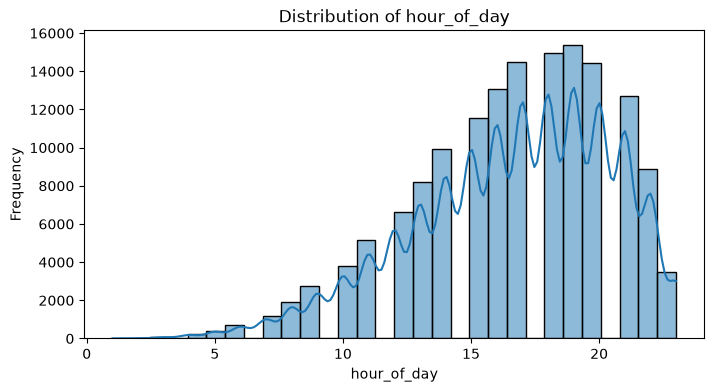

In [54]:

    plt.figure(figsize=(8, 4))
    sns.histplot(df['hour_of_day'], bins=30, kde=True)
    plt.title('Distribution of hour_of_day')
    plt.xlabel('hour_of_day')
    plt.ylabel('Frequency')
    plt.show()

### **Observation**

The number of posts is generally low during the early morning hours and increases during the afternoon and evening. The highest posting activity is observed around the evening hours, while it decreases again at night.

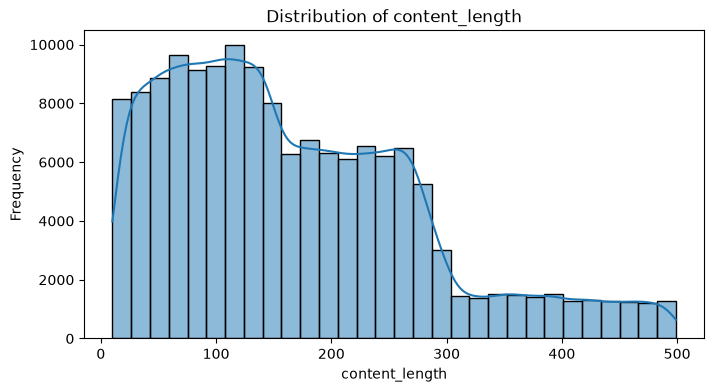

In [62]:
plt.figure(figsize=(8, 4))
sns.histplot(df['content_length'], bins=30, kde=True)
plt.title('Distribution of content_length')
plt.xlabel('content_length')
plt.ylabel('Frequency')
plt.show()

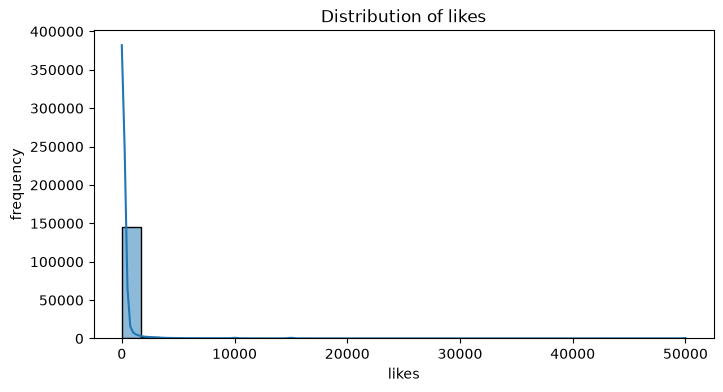

In [60]:
plt.figure(figsize=(8, 4))
sns.histplot(df['likes'], bins=30, kde=True)
plt.title('Distribution of likes')
plt.xlabel('likes')
plt.ylabel('frequency')
plt.show()

In [14]:
categorical_columns = df.select_dtypes(include='str').columns

categorical_columns

Index(['post_id', 'platform', 'timestamp', 'date', 'user_id', 'topic',
       'language', 'media_type', 'sentiment_category', 'location'],
      dtype='str')

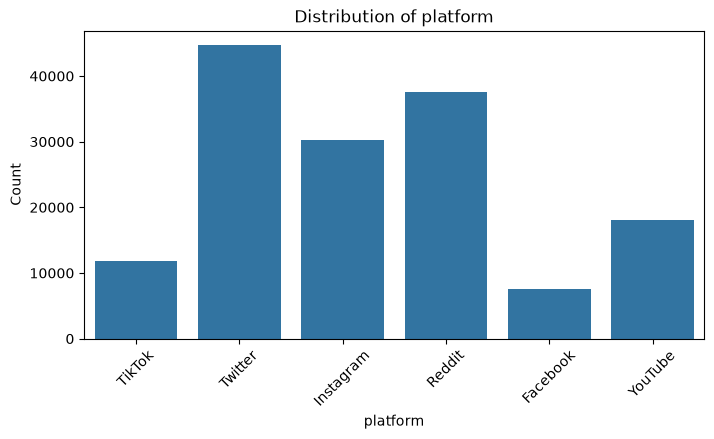

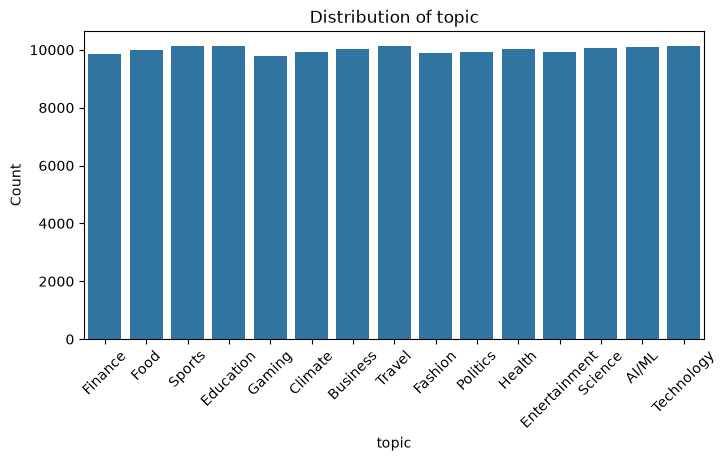

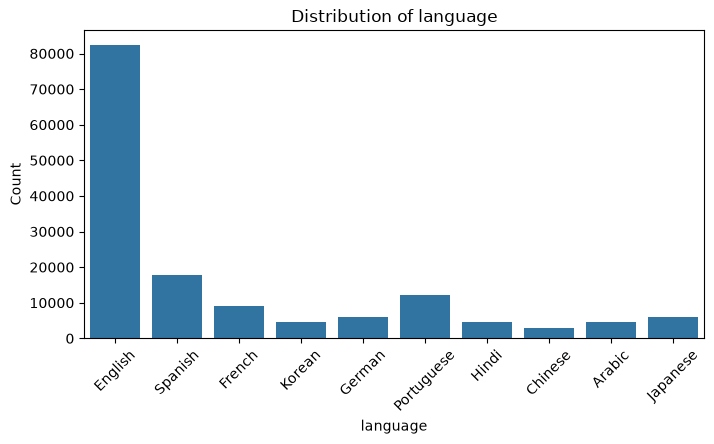

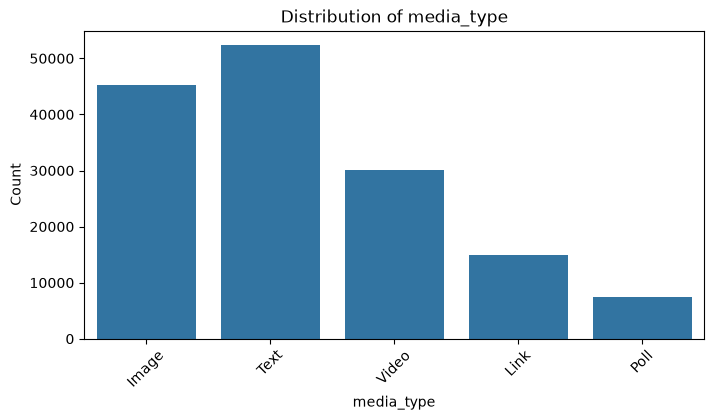

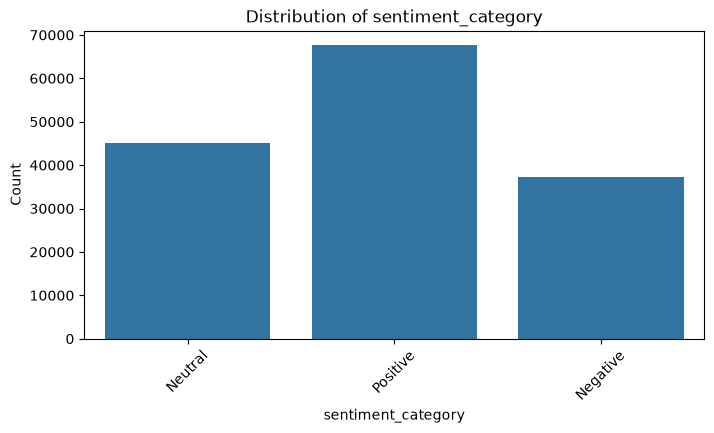

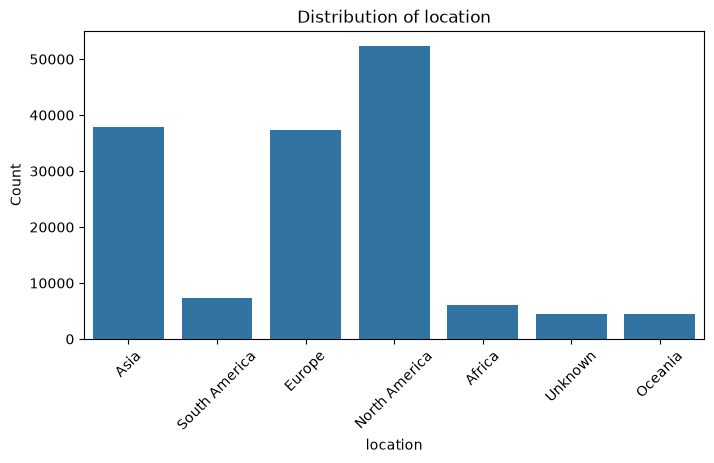

In [15]:
categorical_features = [
    "platform",
    "topic",
    "language",
    "media_type",
    "sentiment_category",
    "location"
]

for column in categorical_features:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=column)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

### for plateform graph
The platform distribution is not uniform. Twitter has the highest number of posts, while Facebook has the lowest number of posts.

### for topic graph
#### Insight
The topic distribution is almost uniform. Each topic has a similar number of posts, so there is no major imbalance among the topics.

### 4->Relationships

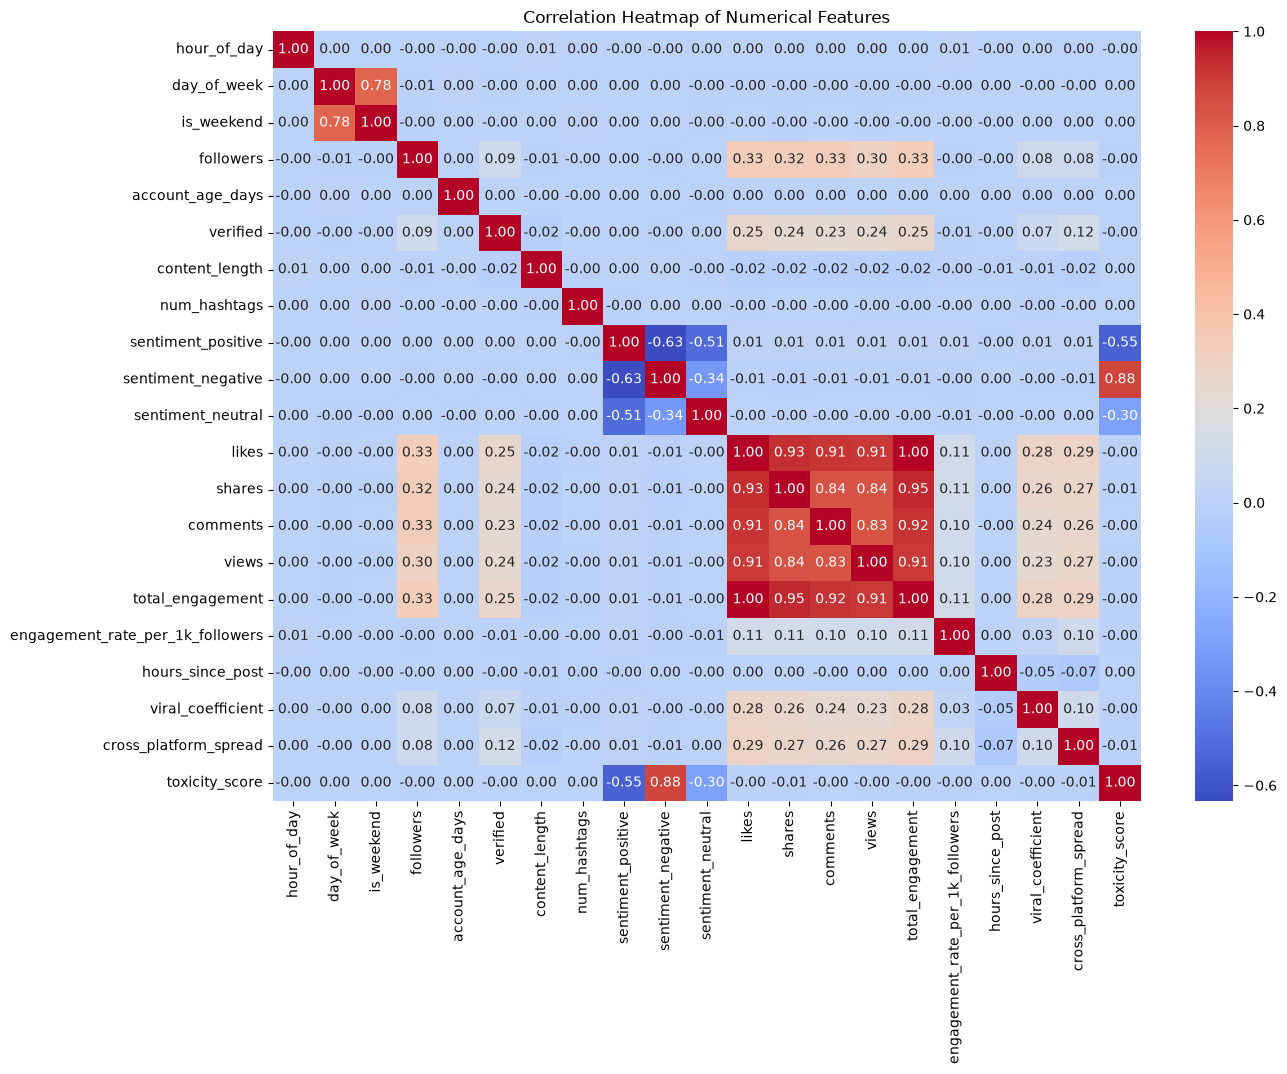

In [16]:
plt.figure(figsize=(14, 10))

correlation = df[numerical_columns].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### **Observation**

The correlation values close to +1 show a strong positive relationship, while values close to -1 show a strong negative relationship. Values close to 0 indicate a weak or very low linear relationship.

In this  likes, shares, comments, and views have strong positive correlations with each other. 

Sentiment positive and sentiment negative have a negative correlation . Toxicity score and sentiment negative have a strong positive correlation .

Many other features have correlation values close to 0, indicating weak linear relationships between them.

#### Bivariate Analysis

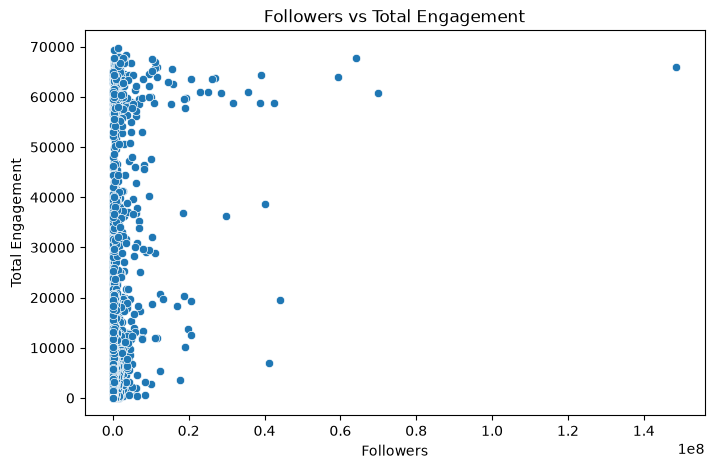

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df,x="followers",y="total_engagement")

plt.title("Followers vs Total Engagement")
plt.xlabel("Followers")
plt.ylabel("Total Engagement")
plt.show()

### **Observation**

The scatter plot shows that most observations are concentrated at lower follower counts. Total engagement varies widely even for accounts with fewer followers.

### **5. Feature Engineering**

Feature engineering is the process of creating new meaningful features from existing features.

In this dataset, we create an 'engagement per view' feature to understand how much engagement a post receives compared to its total views.

In [18]:
df["engagement_per_view"] = (
    df["total_engagement"] / df["views"].replace(0, np.nan)
)

df["engagement_per_view"].head()

0         NaN
1    0.028571
2    0.076923
3    0.032058
4         NaN
Name: engagement_per_view, dtype: float64

In [19]:
df["engagement_per_view"].describe()

count    98947.000000
mean         0.058174
std          0.043004
min          0.020036
25%          0.029373
50%          0.041420
75%          0.069849
max          0.271524
Name: engagement_per_view, dtype: float64

In [20]:
df["engagement_per_follower"] = (
    df["total_engagement"] / df["followers"].replace(0, np.nan)
)

df["engagement_per_follower"].describe()

count    149276.000000
mean          0.057553
std           0.322230
min           0.000000
25%           0.000000
50%           0.004271
75%           0.027322
max          28.076923
Name: engagement_per_follower, dtype: float64

## **PART-2: Principal Component Analysis (PCA)**

PCA is a dimensionality reduction technique. It transforms a large number of numerical features into a smaller number of principal components .

#### Select numerical Features for PCA

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [22]:
pca_features = df.select_dtypes(include=np.number).columns
pca_features

Index(['hour_of_day', 'day_of_week', 'is_weekend', 'followers',
       'account_age_days', 'verified', 'content_length', 'num_hashtags',
       'sentiment_positive', 'sentiment_negative', 'sentiment_neutral',
       'likes', 'shares', 'comments', 'views', 'total_engagement',
       'engagement_rate_per_1k_followers', 'hours_since_post',
       'viral_coefficient', 'cross_platform_spread', 'toxicity_score',
       'engagement_per_view', 'engagement_per_follower'],
      dtype='str')

In [23]:
X_pca = df[pca_features].copy()

In [24]:
X_pca.isnull().sum()

hour_of_day                             0
day_of_week                             0
is_weekend                              0
followers                               0
account_age_days                        0
verified                                0
content_length                          0
num_hashtags                            0
sentiment_positive                      0
sentiment_negative                      0
sentiment_neutral                       0
likes                                   0
shares                                  0
comments                                0
views                                   0
total_engagement                        0
engagement_rate_per_1k_followers        0
hours_since_post                        0
viral_coefficient                       0
cross_platform_spread                   0
toxicity_score                          0
engagement_per_view                 51053
engagement_per_follower               724
dtype: int64

In [25]:
X_pca["engagement_per_view"] = X_pca["engagement_per_view"].fillna(0)

X_pca["engagement_per_follower"] = X_pca["engagement_per_follower"].fillna(0)

### Scaling
Scaling is used to bring numerical features to a comparable scale. Since the features in our dataset have different ranges, 'StandardScaler' is applied before PCA. It standardizes the features to approximately mean 0 and standard deviation 1. This prevents features with larger values from dominating the PCA results.

In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)
X_scaled.shape

(150000, 23)

### Apply PCA

In [27]:
pca = PCA()

X_pca_transformed = pca.fit_transform(X_scaled)
X_pca_transformed.shape

(150000, 23)

In [28]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Explained Variance:")
print(explained_variance)

print("\nCumulative Explained Variance:")
print(cumulative_variance)

Explained Variance:
[2.20482861e-01 1.04360593e-01 8.63852820e-02 7.75031511e-02
 6.32192125e-02 4.66764712e-02 4.55390439e-02 4.35208369e-02
 4.34441769e-02 4.34103179e-02 4.12867666e-02 3.97902880e-02
 3.92436412e-02 3.74411346e-02 3.53529144e-02 9.46277010e-03
 7.39196697e-03 6.93551066e-03 6.33645006e-03 2.20962158e-03
 6.98999006e-06 1.15952850e-12 1.41879568e-16]

Cumulative Explained Variance:
[0.22048286 0.32484345 0.41122874 0.48873189 0.5519511  0.59862757
 0.64416661 0.68768745 0.73113163 0.77454195 0.81582871 0.855619
 0.89486264 0.93230378 0.96765669 0.97711946 0.98451143 0.99144694
 0.99778339 0.99999301 1.         1.         1.        ]


The explained variance shows the amount of information captured by each principal component. The cumulative explained variance shows the total information preserved as more components are added.

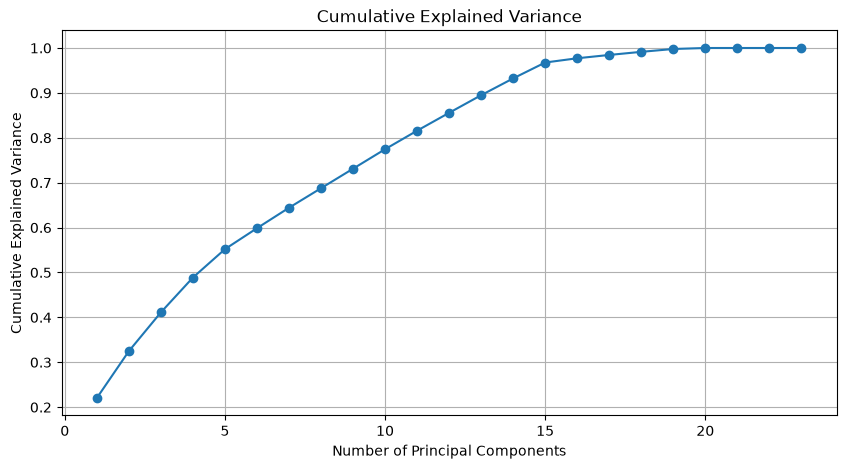

In [29]:
plt.figure(figsize=(10, 5))

components = range(1, len(explained_variance) + 1)

plt.plot(components, cumulative_variance, marker="o")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.grid()
plt.show()

### **Observation**

The cumulative explained variance increases as the number of principal components increases. The first 15 components preserve approximately 96.77% 
of the total variance, showing that PCA can reduce the dimensionality while retaining most of the information.

### **Principal Component Selection**

Based on the cumulative explained variance, the first 15 principal components preserve approximately 96.77% of the total variance. Therefore, 15 principal components are selected for dimensionality reduction.

In [30]:
pca_15 = PCA(n_components=15)

X_pca_15 = pca_15.fit_transform(X_scaled)

X_pca_15.shape

(150000, 15)

A principal component is a new variable created by combining the original numerical features.

Dimensionality reduction reduces the number of features while preserving most of the important information. In this dataset, reducing 23 numerical features to 15 principal components while retaining about 96.77% of the variance can make the data simpler to work with and reduce the complexity of further analysis.

## **PART-4: ENSEMBLE LEARNING — MODEL TRAINING**

In this part, classification is used as the supervised learning task.

The target feature is 'sentiment_category' because it contains categorical sentiment classes. The goal is to predict the sentiment category of a social media post using relevant features from the dataset.

Three ensemble models will be trained and compared:
- Random Forest Classifier
- AdaBoost Classifier
- XGBoost Classifier

In [31]:
X = df.drop("sentiment_category", axis=1)
y = df["sentiment_category"]

In [63]:
X.shape

(150000, 32)

In [32]:
from sklearn.preprocessing import OneHotEncoder

In [33]:
categorical_features = [
    "platform",
    "topic",
    "language",
    "media_type",
    "location"
]

encoder = OneHotEncoder(handle_unknown="ignore")

X_encoded = encoder.fit_transform(X[categorical_features])

In [ ]:
numeric_features = X.select_dtypes(include=np.number).columns

X_numeric = X[numeric_features].fillna(0)

from scipy.sparse import csr_matrix, hstack

X_processed = hstack([csr_matrix(X_numeric.values),X_encoded]).tocsr()

X_processed.shape

(150000, 66)

### **Train-Test Split**

The dataset is divided into training and testing sets using an 80:20 split.

The training data is used to train the machine learning models, while the testing data is used to evaluate their performance.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X_processed, y, test_size=0.20, random_state=42, stratify=y)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120000, 66)
Testing data: (30000, 66)


### **Random Forest Classifier**

Random Forest is a bagging-based ensemble learning algorithm. It builds multiple decision trees and combines their predictions to make the final classification.

In this task, Random Forest is used to predict the "sentiment_category" of social media posts.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100,random_state=42)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

### **AdaBoost Classifier**

AdaBoost is a boosting-based ensemble learning algorithm. It combines multiple weak learners sequentially, giving more importance to the observations that are difficult to classify.

In this task, AdaBoost is used to predict the "sentiment_category" of social media posts.

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(n_estimators=100,random_state=42)

ada_model.fit(X_train, y_train)

y_pred_ada = ada_model.predict(X_test)

### **XGBoost Classifier**

XGBoost is a boosting-based ensemble learning algorithm. It builds decision trees sequentially, where each new tree tries to improve the errors made by the previous trees.

In this task, XGBoost is used to predict the "sentiment_category" of social media posts.

In [38]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_xgb = label_encoder.fit_transform(y_train)
y_test_xgb = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

Classes: ['Negative' 'Neutral' 'Positive']


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(n_estimators=100,random_state=42,eval_metric="mlogloss")

xgb_model.fit(X_train, y_train_xgb)

y_pred_xgb = xgb_model.predict(X_test)

### **Model Evaluation**

The trained models are evaluated using accuracy, precision, recall, and F1-score.

A confusion matrix is also used to understand the classification results of each model.

In [41]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, average="weighted")
rf_recall = recall_score(y_test, y_pred_rf, average="weighted")
rf_f1 = f1_score(y_test, y_pred_rf, average="weighted")

ada_accuracy = accuracy_score(y_test, y_pred_ada)
ada_precision = precision_score(y_test, y_pred_ada, average="weighted")
ada_recall = recall_score(y_test, y_pred_ada, average="weighted")
ada_f1 = f1_score(y_test, y_pred_ada, average="weighted")

xgb_accuracy = accuracy_score(y_test_xgb, y_pred_xgb)
xgb_precision = precision_score(y_test_xgb, y_pred_xgb, average="weighted")
xgb_recall = recall_score(y_test_xgb, y_pred_xgb, average="weighted")
xgb_f1 = f1_score(y_test_xgb, y_pred_xgb, average="weighted")

print("Random Forest")
print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1-score:", rf_f1)

print("\nAdaBoost")
print("Accuracy:", ada_accuracy)
print("Precision:", ada_precision)
print("Recall:", ada_recall)
print("F1-score:", ada_f1)

print("\nXGBoost")
print("Accuracy:", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall:", xgb_recall)
print("F1-score:", xgb_f1)

Random Forest
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

AdaBoost
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

XGBoost
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0


### **Model Comparison**

The performance of Random Forest, AdaBoost, and XGBoost is compared using accuracy, precision, recall, and F1-score.

All three models achieved the same evaluation scores on the test data. 

In [42]:
results = pd.DataFrame({
    "Model": ["Random Forest", "AdaBoost", "XGBoost"],
    "Accuracy": [rf_accuracy, ada_accuracy, xgb_accuracy],
    "Precision": [rf_precision, ada_precision, xgb_precision],
    "Recall": [rf_recall, ada_recall, xgb_recall],
    "F1-Score": [rf_f1, ada_f1, xgb_f1]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,1.0,1.0,1.0,1.0
1,AdaBoost,1.0,1.0,1.0,1.0
2,XGBoost,1.0,1.0,1.0,1.0


### **Confusion Matrix**

A confusion matrix shows the number of correctly and incorrectly classified samples for each sentiment category.

It helps us understand the classification performance of each model for individual classes.

In [43]:
from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(y_test, y_pred_rf)
ada_cm = confusion_matrix(y_test, y_pred_ada)
xgb_cm = confusion_matrix(y_test_xgb, y_pred_xgb)

print("Random Forest Confusion Matrix:")
print(rf_cm)

print("\nAdaBoost Confusion Matrix:")
print(ada_cm)

print("\nXGBoost Confusion Matrix:")
print(xgb_cm)

Random Forest Confusion Matrix:
[[ 7459     0     0]
 [    0  9022     0]
 [    0     0 13519]]

AdaBoost Confusion Matrix:
[[ 7459     0     0]
 [    0  9022     0]
 [    0     0 13519]]

XGBoost Confusion Matrix:
[[ 7459     0     0]
 [    0  9022     0]
 [    0     0 13519]]


### **Confusion Matrix Visualization**



#### Confusion matrix for Random forest

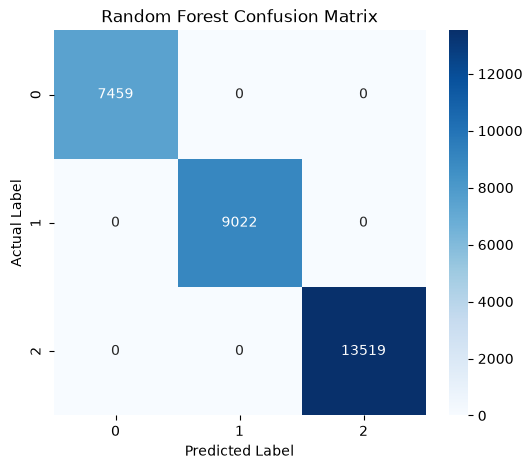

In [44]:
plt.figure(figsize=(6, 5))
sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

#### Confusion matrix for AdaBoost

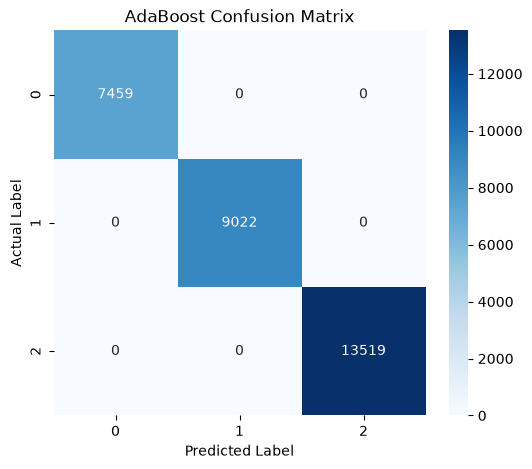

In [45]:
plt.figure(figsize=(6, 5))
sns.heatmap(ada_cm, annot=True, fmt="d", cmap="Blues")
plt.title("AdaBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

#### Confusion matrix for XGBoost

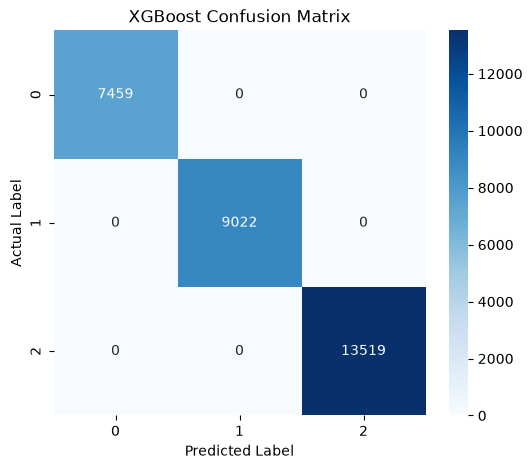

In [46]:
plt.figure(figsize=(6, 5))
sns.heatmap(xgb_cm, annot=True, fmt="d", cmap="Blues")
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### **Confusion Matrix Observation**

The confusion matrices of Random Forest, AdaBoost, and XGBoost show the same results.

For all three models, 7,459 samples of class 0, 9,022 samples of class 1, and 13,519 samples of class 2 were correctly classified.

There are no misclassified samples in the test data. Therefore, all three models achieved the same classification result on the given test set.


### **Feature Importance**

Feature importance shows the relative contribution of features to the predictions made by an ensemble model.

It helps identify which features are more important for predicting the target variable.

In [ ]:
feature_names = list(numeric_features) + list(encoder.get_feature_names_out(categorical_features))

feature_importance = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(by="Importance",ascending=False)

importance_df.head(10)

,Feature,Importance
8,sentiment_positive,0.328289
10,sentiment_neutral,0.293311
9,sentiment_negative,0.227137
20,toxicity_score,0.145250
4,account_age_days,0.000435
3,followers,0.000423
6,content_length,0.000410
17,hours_since_post,0.000402
22,engagement_per_follower,0.000378
16,engagement_rate_per_1k_followers,0.000346


### **Feature Importance Observation**

The feature importance results show that "sentiment_positive", "sentiment_neutral", and "sentiment_negative" are the most important features in the Random Forest model.

"toxicity_score" also has relatively high importance compared with the other features.

Features such as 'account_age_days', 'followers', and 'content_length' have much lower importance in the model.

The high importance of the sentiment-related features should be considered while interpreting the perfect model scores because these features are closely related to the target 'sentiment_category'.

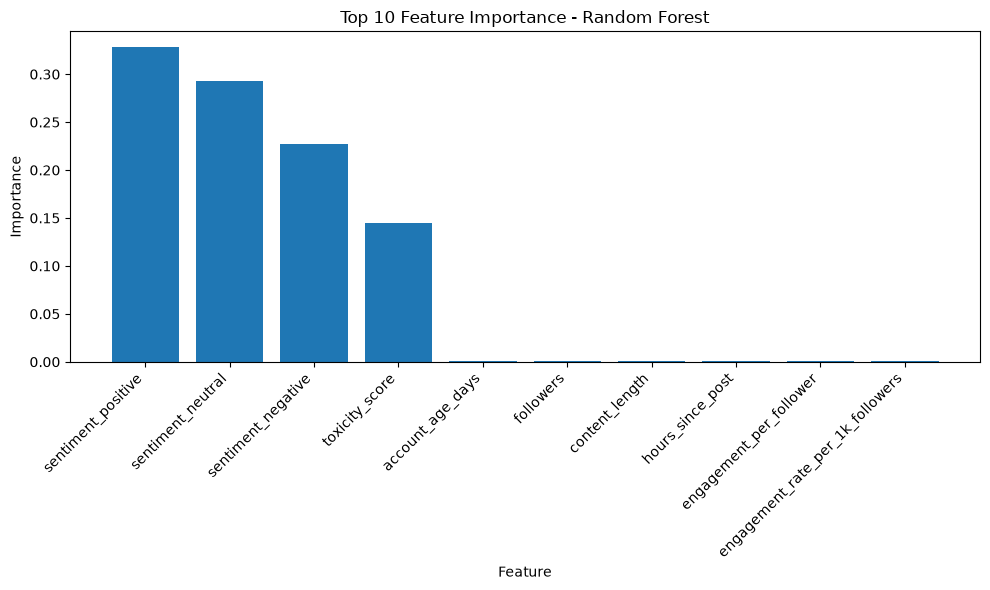

In [ ]:
plt.figure(figsize=(10, 6))

top_features = importance_df.head(10)

plt.bar(top_features["Feature"],top_features["Importance"])

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Top 10 Feature Importance - Random Forest")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## **Bagging and Boosting**

### **Bagging**

Bagging is an ensemble technique in which multiple models are trained independently on different random samples of the training data. Their predictions are combined to improve the overall result and reduce variance.

Random Forest uses bagging by training multiple decision trees on different samples and combining their predictions.

### **Boosting**

Boosting is an ensemble technique in which models are trained sequentially. Each new model focuses on improving the errors made by the previous models.

AdaBoost and XGBoost are boosting-based algorithms. They combine multiple learners to make the final prediction.

### **Part 4 Summary**

Random Forest, AdaBoost, and XGBoost were trained to predict the 'sentiment_category' using the same 80:20 train-test split.

All three models achieved an accuracy, precision, recall, and F1-score of 1.00 on the test set. Their confusion matrices also showed no misclassified samples.

The sentiment-related features had the highest importance in the Random Forest model. Since these features are closely related to the target category, the perfect scores should be interpreted cautiously as possible target leakage.

# **PART-5: MODEL EXPORT AND SAVING**


## **Saving the Trained Model and Preprocessing Information**

Random Forest is selected for model export because all three trained models achieved the same evaluation scores.


In [49]:
import joblib

joblib.dump(rf_model, "random_forest_model.pkl")

preprocessing_info = {
    "encoder": encoder,
    "numeric_features": list(numeric_features),
    "categorical_features": list(categorical_features)
}

joblib.dump(preprocessing_info, "preprocessing.pkl")

print("Model and preprocessing information saved successfully.")

Model and preprocessing information saved successfully.


In [ ]:
loaded_model = joblib.load("random_forest_model.pkl")

test_predictions = loaded_model.predict(X_test[:5])

print("Reloaded model predictions:")
print(test_predictions)

print("\nOriginal model predictions:")
print(rf_model.predict(X_test[:5]))

print("\nSame predictions:",np.array_equal(test_predictions, rf_model.predict(X_test[:5])))

Reloaded model predictions:
['Positive' 'Positive' 'Neutral' 'Neutral' 'Negative']

Original model predictions:
['Positive' 'Positive' 'Neutral' 'Neutral' 'Negative']

Same predictions: True



After saving, the model was loaded again and tested with sample test data. The predictions from the loaded model were the same as the original model, confirming that the model was saved and loaded correctly.